# Exploratory Data Analysis of Airline Delays and Cancellations

**Name:** Ahmadreza Jafari
**Student ID:** 403222080
**Course:** Data Science — Shahid Beheshti University, Spring 2026
**Instructor:** Dr. Kheradpisheh


**Subset used:** Yearly CSV files for **2015, 2016, and 2017**, each containing one row per domestic
US flight with carrier, origin/destination, scheduled and actual times, delay measures, cancellation and
diversion indicators, elapsed time, distance, and delay-cause breakdowns.

**Task description:** This notebook performs a structured exploratory data analysis (EDA) of the three
years of flight data: data understanding and cleaning, derived variables, univariate summaries, time
patterns, carrier/airport comparisons, bivariate relationships, and a correlation/delay-cause summary.


## 0. Imports and configuration

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display / plotting configuration
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


DATA_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in dir() else '.'
YEARS = [2015, 2016, 2017]


## 1. Data understanding and preparation

### 1.1 Loading the three years of data

The raw files are large (millions of rows per year), so we specify dtypes up front where possible and
parse the flight date as a datetime column at load time. We concatenate the three years into a single
dataframe and keep a `YEAR` column (redundant with `FL_DATE` but convenient for grouping).


In [ ]:
''' Columns and a reasonable dtype hint for each, based on the documented schema.
 We keep only the columns the analysis actually uses — dropping the nine unused
 timing/identifier columns (WHEELS_OFF, WHEELS_ON, DEP_TIME, ARR_TIME, CRS_ARR_TIME,
 CRS_ELAPSED_TIME, ACTUAL_ELAPSED_TIME, AIR_TIME, OP_CARRIER_FL_NUM) cuts memory
 by roughly a third, which matters on a 16 GB machine loading ~17M rows.
 Float columns are read as float32 (precision is ample for EDA on values up to
 a few thousand minutes/miles). '''
loat32_cols = [
    'DEP_DELAY', 'TAXI_OUT', 'TAXI_IN', 'ARR_DELAY', 'CANCELLED', 'DIVERTED',
    'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY',
    'LATE_AIRCRAFT_DELAY',
]
dtype_map = {
    'OP_CARRIER': 'object',
    'ORIGIN': 'object',
    'DEST': 'object',
    'CRS_DEP_TIME': 'Int64',
    'CANCELLATION_CODE': 'object',
}
for c in float32_cols:
    dtype_map[c] = 'float32'

frames = []
for year in YEARS:
    parquet_path = os.path.join(DATA_DIR, f'{year}.parquet')
    csv_path = os.path.join(DATA_DIR, f'{year}.csv')
    if os.path.exists(parquet_path):
        df_year = pd.read_parquet(parquet_path)
    else:
        df_year = pd.read_csv(
            csv_path,
            dtype=dtype_map,
            parse_dates=['FL_DATE'],
            usecols=lambda c: c != 'Unnamed: 27',
        )
    df_year['YEAR'] = year
    frames.append(df_year)

flights = pd.concat(frames, ignore_index=True)
del frames
print(f'Loaded {len(flights):,} rows and {flights.shape[1]} columns across {len(YEARS)} years.')


Loaded 17,111,358 rows and 19 columns across 3 years.


In [3]:
# Cast low-cardinality identifier columns to 'category' to save memory and speed up groupbys.
for c in ['OP_CARRIER', 'ORIGIN', 'DEST', 'CANCELLATION_CODE']:
    flights[c] = flights[c].astype('category')

flights.head()


,FL_DATE,OP_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,DEP_DELAY,TAXI_OUT,TAXI_IN,ARR_DELAY,CANCELLED,CANCELLATION_CODE,DIVERTED,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,YEAR
0,2015-01-01,NK,MCO,FLL,2147,-4.0,15.0,7.0,-5.0,0.0,NaN,0.0,177.0,NaN,NaN,NaN,NaN,NaN,2015
1,2015-01-01,NK,LGA,FLL,1050,14.0,20.0,9.0,-1.0,0.0,NaN,0.0,1076.0,NaN,NaN,NaN,NaN,NaN,2015
2,2015-01-01,NK,FLL,MCO,700,12.0,19.0,10.0,16.0,0.0,NaN,0.0,177.0,0.0,0.0,16.0,0.0,0.0,2015
3,2015-01-01,NK,IAH,LAS,2240,11.0,8.0,4.0,-9.0,0.0,NaN,0.0,1222.0,NaN,NaN,NaN,NaN,NaN,2015
4,2015-01-01,NK,IAH,ORD,623,-3.0,15.0,10.0,-15.0,0.0,NaN,0.0,925.0,NaN,NaN,NaN,NaN,NaN,2015


In [4]:
flights.info()


<class 'pandas.DataFrame'>
RangeIndex: 17111358 entries, 0 to 17111357
Data columns (total 19 columns):
 #   Column               Dtype         
---  ------               -----         
 0   FL_DATE              datetime64[us]
 1   OP_CARRIER           category      
 2   ORIGIN               category      
 3   DEST                 category      
 4   CRS_DEP_TIME         int16         
 5   DEP_DELAY            float32       
 6   TAXI_OUT             float32       
 7   TAXI_IN              float32       
 8   ARR_DELAY            float32       
 9   CANCELLED            float32       
 10  CANCELLATION_CODE    category      
 11  DIVERTED             float32       
 12  DISTANCE             float32       
 13  CARRIER_DELAY        float32       
 14  WEATHER_DELAY        float32       
 15  NAS_DELAY            float32       
 16  SECURITY_DELAY       float32       
 17  LATE_AIRCRAFT_DELAY  float32       
 18  YEAR                 int64         
dtypes: category(4), datetime64[us]

In [5]:
flights.describe(include='number').T


,count,mean,std,min,25%,50%,75%,max
CRS_DEP_TIME,17111358.0,1330.184008,488.059978,1.0,915.0,1325.0,1735.0,2359.0
DEP_DELAY,16881406.0,9.345809,40.310230,-234.0,-5.0,-2.0,6.0,2755.0
TAXI_OUT,16874748.0,16.345675,9.037231,0.0,11.0,14.0,19.0,225.0
TAXI_IN,16866327.0,7.465423,5.751210,0.0,4.0,6.0,9.0,414.0
ARR_DELAY,16831563.0,4.088201,42.402172,-238.0,-14.0,-6.0,7.0,2189.0
CANCELLED,17111358.0,0.013934,0.117219,0.0,0.0,0.0,0.0,1.0
DIVERTED,17111358.0,0.002418,0.049110,0.0,0.0,0.0,0.0,1.0
DISTANCE,17111358.0,842.843323,617.391174,21.0,386.0,672.0,1084.0,4983.0
CARRIER_DELAY,3057151.0,19.699059,56.126698,0.0,0.0,1.0,18.0,2142.0
WEATHER_DELAY,3057151.0,2.782354,22.116985,0.0,0.0,0.0,0.0,1934.0


**Notes on the output above:**
- `head()` shows individual flight records: one row per operated (or scheduled, if cancelled) flight,
  identified by carrier code (`OP_CARRIER`), flight number, origin/destination airport codes, and a mix
  of scheduled (`CRS_*`) and actual timing/delay fields.
- `info()` confirms the row count, dtypes, and gives a first look at which columns have large numbers
  of missing values (visible as a gap between `non-null count` and total rows) — mainly the delay-cause
  columns and fields that only apply to cancelled or diverted flights.
- `describe()` on the numeric columns gives means, standard deviations, and quantiles that already
  hint at right-skew in the delay columns (mean well above median) and at implausible or extreme values
  worth checking (e.g. very large `DEP_DELAY` / `ARR_DELAY`).


### 1.2 Key fields used in this analysis

| Field | Category | Description |
|---|---|---|
| `FL_DATE` | Identifier / time | Flight date |
| `OP_CARRIER` | Identifier | Operating carrier code (2-letter) |
| `OP_CARRIER_FL_NUM` | Identifier | Flight number |
| `ORIGIN`, `DEST` | Identifier | Origin / destination airport code |
| `CRS_DEP_TIME`, `CRS_ARR_TIME` | Time | Scheduled departure / arrival time (local, HHMM) |
| `DEP_TIME`, `ARR_TIME` | Time | Actual departure / arrival time (HHMM) |
| `DEP_DELAY`, `ARR_DELAY` | Delay measure | Departure / arrival delay in minutes (negative = early) |
| `TAXI_OUT`, `TAXI_IN` | Time | Taxi-out / taxi-in duration in minutes |
| `CANCELLED`, `CANCELLATION_CODE` | Indicator | Cancellation flag and reason code (A/B/C/D) |
| `DIVERTED` | Indicator | Diversion flag |
| `CRS_ELAPSED_TIME`, `ACTUAL_ELAPSED_TIME`, `AIR_TIME` | Time | Scheduled / actual elapsed time, airborne time |
| `DISTANCE` | Numeric | Great-circle distance in miles |
| `CARRIER_DELAY`, `WEATHER_DELAY`, `NAS_DELAY`, `SECURITY_DELAY`, `LATE_AIRCRAFT_DELAY` | Delay measure | Minutes of delay attributed to each cause (only populated when `ARR_DELAY` ≥ 15) |

### 1.3 Transformations applied
- Parsed `FL_DATE` as a proper `datetime64` column (enables `.dt.month`, `.dt.dayofweek`, etc.).
- Cast `OP_CARRIER`, `ORIGIN`, `DEST`, `CANCELLATION_CODE` to `category` dtype.
- Added a `YEAR` column extracted at load time (also derivable from `FL_DATE`).
- Derived variables are introduced in Section 1.5 below.


## 1.4 Missing data and data quality

In [6]:
missing = flights.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(flights) * 100).round(2)
missing_summary = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_summary = missing_summary[missing_summary['missing_count'] > 0]
missing_summary


,missing_count,missing_pct
CANCELLATION_CODE,16872920,98.61
SECURITY_DELAY,14054207,82.13
CARRIER_DELAY,14054207,82.13
NAS_DELAY,14054207,82.13
WEATHER_DELAY,14054207,82.13
LATE_AIRCRAFT_DELAY,14054207,82.13
ARR_DELAY,279795,1.64
TAXI_IN,245031,1.43
TAXI_OUT,236610,1.38
DEP_DELAY,229952,1.34


**Interpreting the pattern of missingness:**
- The five delay-cause columns (`CARRIER_DELAY`, `WEATHER_DELAY`, `NAS_DELAY`, `SECURITY_DELAY`,
  `LATE_AIRCRAFT_DELAY`) are expected to show the highest missingness. Per the dataset documentation,
  these are only populated by the reporting carrier when a flight's arrival delay is at least 15 minutes;
  for flights delayed less than that (or not delayed / cancelled), the fields are legitimately absent rather
  than "missing" in the data-quality sense. We treat `NaN` in these columns as "no delay of this cause /
  not applicable", **not** as a value to impute.
- `DEP_TIME`, `ARR_TIME`, `DEP_DELAY`, `ARR_DELAY`, `TAXI_OUT`, `TAXI_IN`, `AIR_TIME`,
  `ACTUAL_ELAPSED_TIME` are missing almost exclusively for **cancelled** flights, since a cancelled flight
  never actually departs or arrives. We verify this below.
- `CANCELLATION_CODE` is missing for the vast majority of rows because it is only populated when
  `CANCELLED == 1`.


In [7]:
# Verify that missingness in DEP_DELAY / ARR_DELAY lines up almost entirely with cancelled flights.
cancelled_mask = flights['CANCELLED'] == 1
dep_missing_and_cancelled = (flights['DEP_DELAY'].isna() & cancelled_mask).sum()
dep_missing_total = flights['DEP_DELAY'].isna().sum()
print(f"DEP_DELAY missing: {dep_missing_total:,} rows; of these, {dep_missing_and_cancelled:,} "
      f"({dep_missing_and_cancelled / max(dep_missing_total,1):.1%}) are cancelled flights.")

arr_missing_and_cancelled = (flights['ARR_DELAY'].isna() & cancelled_mask).sum()
arr_missing_total = flights['ARR_DELAY'].isna().sum()
print(f"ARR_DELAY missing: {arr_missing_total:,} rows; of these, {arr_missing_and_cancelled:,} "
      f"({arr_missing_and_cancelled / max(arr_missing_total,1):.1%}) are cancelled flights.")


DEP_DELAY missing: 229,952 rows; of these, 229,951 (100.0%) are cancelled flights.
ARR_DELAY missing: 279,795 rows; of these, 238,438 (85.2%) are cancelled flights.


**How missing values are handled in the rest of this notebook:**
- When counting flights (by carrier, airport, month, etc.) we keep all rows, including cancelled flights,
  since a cancelled flight is still a scheduled operation worth counting.
- When analysing the *distribution* of arrival/departure delay (histograms, means by group), we drop
  rows with missing `ARR_DELAY` / `DEP_DELAY`, since a cancelled flight has no realised delay value.
- When summarising delay causes, we restrict to rows where `ARR_DELAY >= 15` (the population for which
  the cause columns are meaningfully populated) and treat remaining `NaN`s in the five cause columns as 0.


## 1.5 Derived variables

We define the following derived variables:

1. **`ARR_DEL15`** — binary indicator, 1 if `ARR_DELAY >= 15`, else 0 (flights with missing `ARR_DELAY`,
   i.e. cancelled flights, are left as `NaN` here and excluded from delay-rate calculations unless noted).
2. **`DEP_HOUR`** — the scheduled departure hour (0–23), extracted from `CRS_DEP_TIME`.
3. **`TIME_OF_DAY`** — a categorical bucket derived from `DEP_HOUR`: Night (0–5), Morning (6–11),
   Afternoon (12–17), Evening (18–23).
4. **`DAY_OF_WEEK`** — day of week name derived from `FL_DATE`.
5. **`TOTAL_DELAY_CAUSE_MIN`** — sum of the five delay-cause columns (treating `NaN` as 0); only
   meaningful for flights with `ARR_DELAY >= 15`.
6. **`MAIN_DELAY_CAUSE`** — the name of whichever of the five cause columns is largest for a given row
   (only computed for delayed flights with at least one non-zero cause).


In [ ]:
# 1. Binary indicator for delayed arrival (>= 15 minutes)
flights['ARR_DEL15'] = np.where(flights['ARR_DELAY'].isna(), np.nan, (flights['ARR_DELAY'] >= 15).astype(float))

# 2. Scheduled departure hour, from CRS_DEP_TIME (HHMM as an integer, e.g. 2147 -> 21)
flights['DEP_HOUR'] = (flights['CRS_DEP_TIME'] // 100).clip(0, 23)

# 3. Time-of-day bucket
def time_of_day(hour):
    if pd.isna(hour):
        return np.nan
    hour = int(hour)
    if 0 <= hour <= 5:
        return 'Night'
    elif 6 <= hour <= 11:
        return 'Morning'
    elif 12 <= hour <= 17:
        return 'Afternoon'
    else:
        return 'Evening'

flights['TIME_OF_DAY'] = flights['DEP_HOUR'].apply(time_of_day)
flights['TIME_OF_DAY'] = pd.Categorical(
    flights['TIME_OF_DAY'], categories=['Morning', 'Afternoon', 'Evening', 'Night'], ordered=True
)

# 4. Day of week name
flights['DAY_OF_WEEK'] = flights['FL_DATE'].dt.day_name()
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
flights['DAY_OF_WEEK'] = pd.Categorical(flights['DAY_OF_WEEK'], categories=dow_order, ordered=True)

# 5. Total delay-cause minutes (NaN -> 0 before summing)
cause_cols = ['CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']
flights['TOTAL_DELAY_CAUSE_MIN'] = flights[cause_cols].fillna(0).sum(axis=1)


has_cause_data = flights[cause_cols].notna().any(axis=1)
main_cause = pd.Series(index=flights.index, dtype='object')
main_cause.loc[has_cause_data] = flights.loc[has_cause_data, cause_cols].fillna(0).idxmax(axis=1)
flights['MAIN_DELAY_CAUSE'] = main_cause.astype('category')

flights[['ARR_DELAY', 'ARR_DEL15', 'DEP_HOUR', 'TIME_OF_DAY', 'DAY_OF_WEEK',
         'TOTAL_DELAY_CAUSE_MIN', 'MAIN_DELAY_CAUSE']].head()


,ARR_DELAY,ARR_DEL15,DEP_HOUR,TIME_OF_DAY,DAY_OF_WEEK,TOTAL_DELAY_CAUSE_MIN,MAIN_DELAY_CAUSE
0,-5.0,0.0,21,Evening,Thursday,0.0,NaN
1,-1.0,0.0,10,Morning,Thursday,0.0,NaN
2,16.0,1.0,7,Morning,Thursday,16.0,NAS_DELAY
3,-9.0,0.0,22,Evening,Thursday,0.0,NaN
4,-15.0,0.0,6,Morning,Thursday,0.0,NaN


## 2. Univariate analysis

### 2.1 Flight counts and distributions

YEAR
2015    5819079
2016    5617658
2017    5674621
dtype: int64


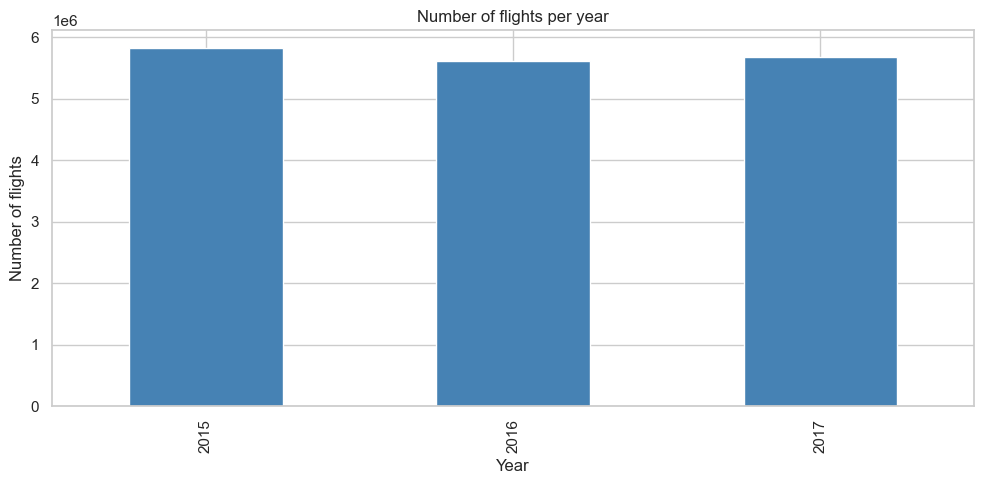

In [9]:
flights_per_year = flights.groupby('YEAR', observed=True).size()
print(flights_per_year)

fig, ax = plt.subplots()
flights_per_year.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Number of flights per year')
ax.set_xlabel('Year')
ax.set_ylabel('Number of flights')
plt.tight_layout()
plt.show()


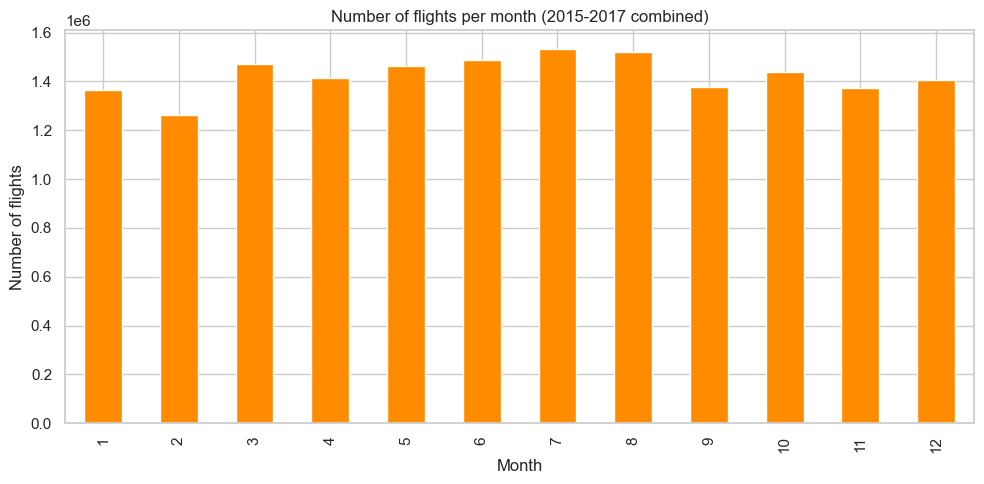

In [10]:
flights['MONTH'] = flights['FL_DATE'].dt.month
flights_per_month = flights.groupby('MONTH', observed=True).size()

fig, ax = plt.subplots()
flights_per_month.plot(kind='bar', ax=ax, color='darkorange')
ax.set_title('Number of flights per month (2015-2017 combined)')
ax.set_xlabel('Month')
ax.set_ylabel('Number of flights')
plt.tight_layout()
plt.show()


_Interpretation._ Flight volume is  stable across the three years
(2015: 5,819,079; 2016: 5,617,658; 2017: 5,674,621 flights).
By month, the summer travel season (June-August, ~1.5M flights each) and March
(~1.47M, spring break) show the highest volumes, while February (~1.26M, the
shortest month) is consistently the lowest.

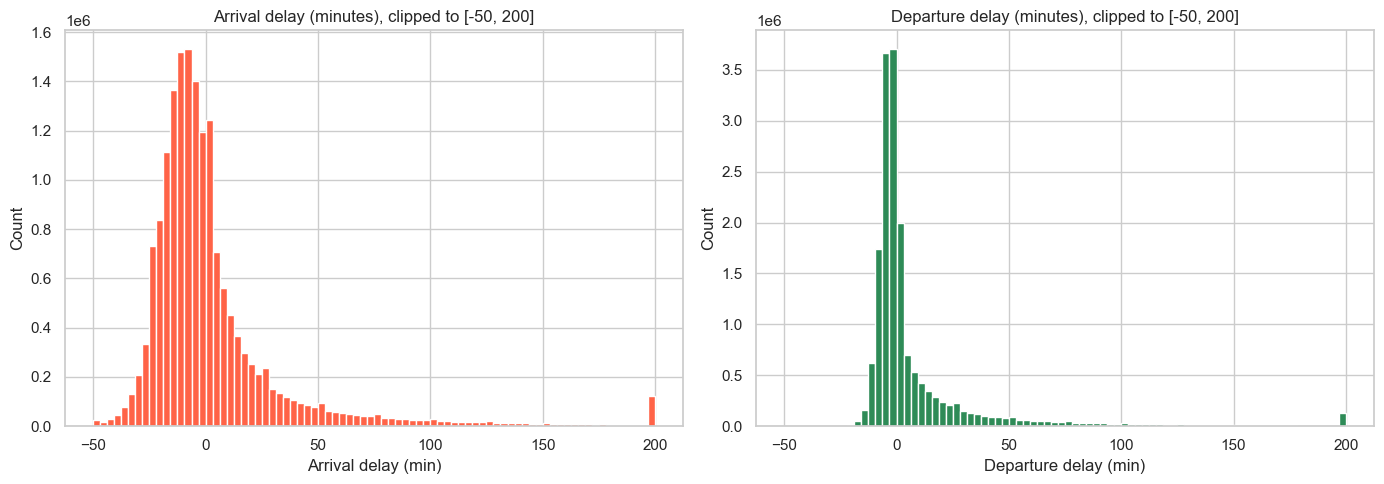

count    1.683156e+07
mean     4.088201e+00
std      4.240217e+01
min     -2.380000e+02
25%     -1.400000e+01
50%     -6.000000e+00
75%      7.000000e+00
max      2.189000e+03
Name: ARR_DELAY, dtype: float64


count    1.688141e+07
mean     9.345809e+00
std      4.031023e+01
min     -2.340000e+02
25%     -5.000000e+00
50%     -2.000000e+00
75%      6.000000e+00
max      2.755000e+03
Name: DEP_DELAY, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

flights['ARR_DELAY'].dropna().clip(-50, 200).hist(bins=80, ax=axes[0], color='tomato')
axes[0].set_title('Arrival delay (minutes), clipped to [-50, 200]')
axes[0].set_xlabel('Arrival delay (min)')
axes[0].set_ylabel('Count')

flights['DEP_DELAY'].dropna().clip(-50, 200).hist(bins=80, ax=axes[1], color='seagreen')
axes[1].set_title('Departure delay (minutes), clipped to [-50, 200]')
axes[1].set_xlabel('Departure delay (min)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

print(flights['ARR_DELAY'].describe())
print(flights['DEP_DELAY'].describe())


_Interpretation._ Both delay distributions are strongly right-skewed. The
median arrival delay is -6 min and the median departure delay is -2 min, i.e.
a typical flight actually arrives/departs a few minutes early. The means are
positive (ARR_DELAY mean = 4.09 min, DEP_DELAY mean = 9.35 min) and far above the
medians, pulled up by a long right tail of large delays; the maxima are 2,189 min
(arrival) and 2,755 min (departure), i.e. delays of well over a day. The 75th
percentile is still only +7 min (arrival) / +6 min (departure), so the bulk of
flights run close to schedule. Clipping to [-50, 200] for the histogram is purely
visual; the extreme tail is visible in describe().max.

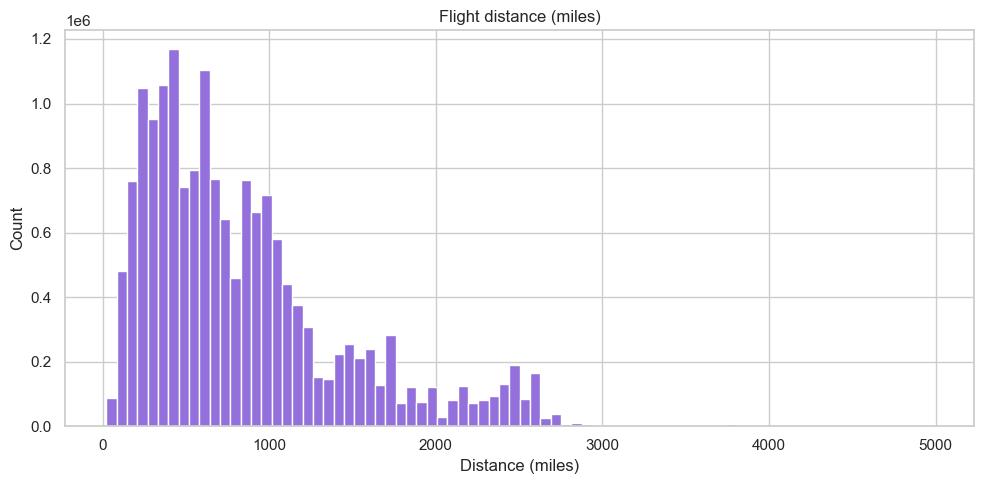

count    1.711136e+07
mean     8.428433e+02
std      6.173912e+02
min      2.100000e+01
25%      3.860000e+02
50%      6.720000e+02
75%      1.084000e+03
max      4.983000e+03
Name: DISTANCE, dtype: float64


In [12]:
fig, ax = plt.subplots()
flights['DISTANCE'].dropna().hist(bins=80, ax=ax, color='mediumpurple')
ax.set_title('Flight distance (miles)')
ax.set_xlabel('Distance (miles)')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

print(flights['DISTANCE'].describe())


### 2.2 Categorical variables

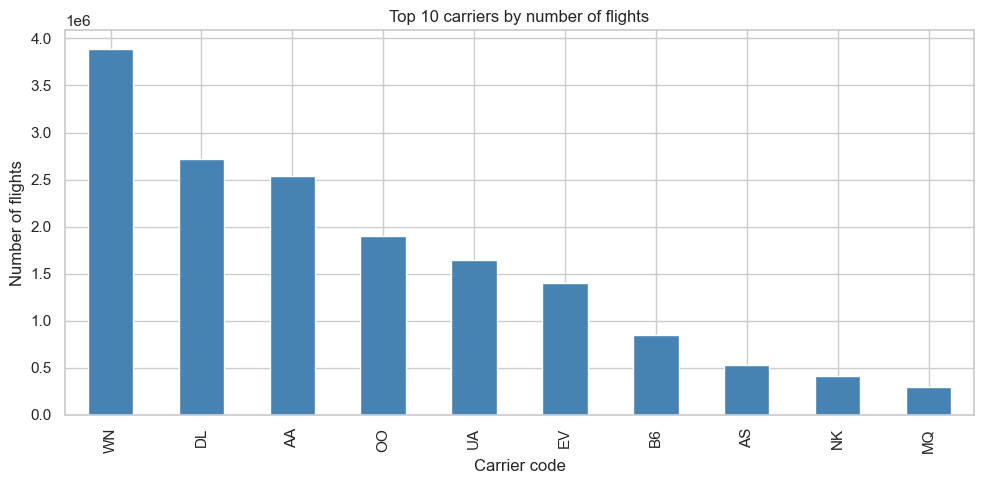

OP_CARRIER
WN    3890743
DL    2722187
AA    2536827
OO    1900813
UA    1645271
EV    1402508
B6     848175
AS     534869
NK     412396
MQ     294632
Name: count, dtype: int64

In [13]:
top_carriers = flights['OP_CARRIER'].value_counts().head(10)

fig, ax = plt.subplots()
top_carriers.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Top 10 carriers by number of flights')
ax.set_xlabel('Carrier code')
ax.set_ylabel('Number of flights')
plt.tight_layout()
plt.show()

top_carriers


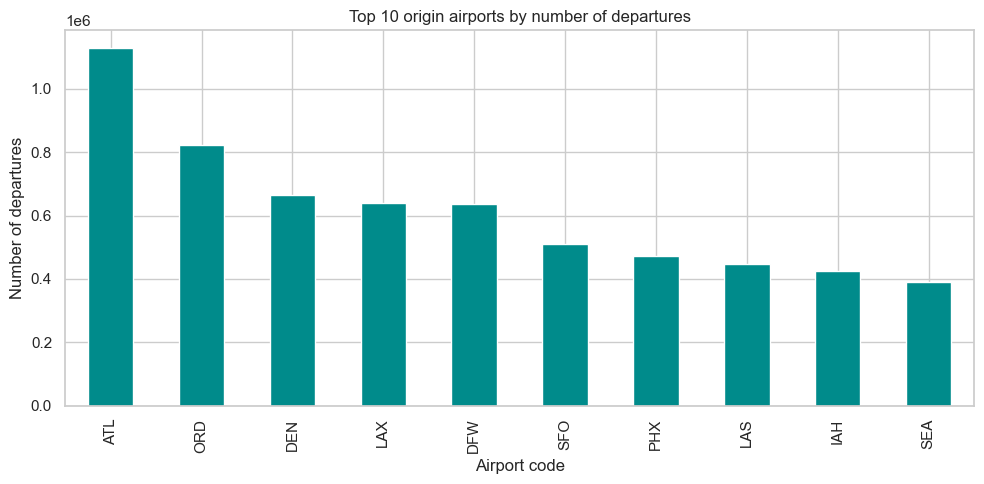

ORIGIN
ATL    1128454
ORD     824078
DEN     663492
LAX     639681
DFW     637852
SFO     509167
PHX     473370
LAS     448275
IAH     426196
SEA     391088
Name: count, dtype: int64

In [14]:
top_origins = flights['ORIGIN'].value_counts().head(10)

fig, ax = plt.subplots()
top_origins.plot(kind='bar', ax=ax, color='darkcyan')
ax.set_title('Top 10 origin airports by number of departures')
ax.set_xlabel('Airport code')
ax.set_ylabel('Number of departures')
plt.tight_layout()
plt.show()

top_origins


In [15]:
cancel_divert_summary = pd.DataFrame({
    'proportion': [flights['CANCELLED'].mean(), flights['DIVERTED'].mean()]
}, index=['Cancelled', 'Diverted'])
cancel_divert_summary['pct'] = (cancel_divert_summary['proportion'] * 100).round(3)
cancel_divert_summary


,proportion,pct
Cancelled,0.013934,1.393
Diverted,0.002418,0.242


_Interpretation._ The dataset is dominated by a small number of large
network and low-cost carriers: Southwest (WN, 3.89M flights), Delta (DL, 2.72M),
American (AA, 2.54M), SkyWest (OO, 1.90M), and United (UA, 1.65M). The busiest
origin airports are the major hubs - Atlanta (ATL, 1.13M departures), Chicago
O'Hare (ORD, 0.82M), Denver (DEN, 0.66M), Los Angeles (LAX, 0.64M), and
Dallas/Fort Worth (DFW, 0.64M) - consistent with the hub-and-spoke structure of
US domestic air travel. Only 1.39% of flights are cancelled and 0.24% are
diverted, so in absolute terms these are rare events even though they affect a
large number of passengers when scaled to 17M flights.

## 3. Time patterns

### 3.1 Delay and flight volume over time

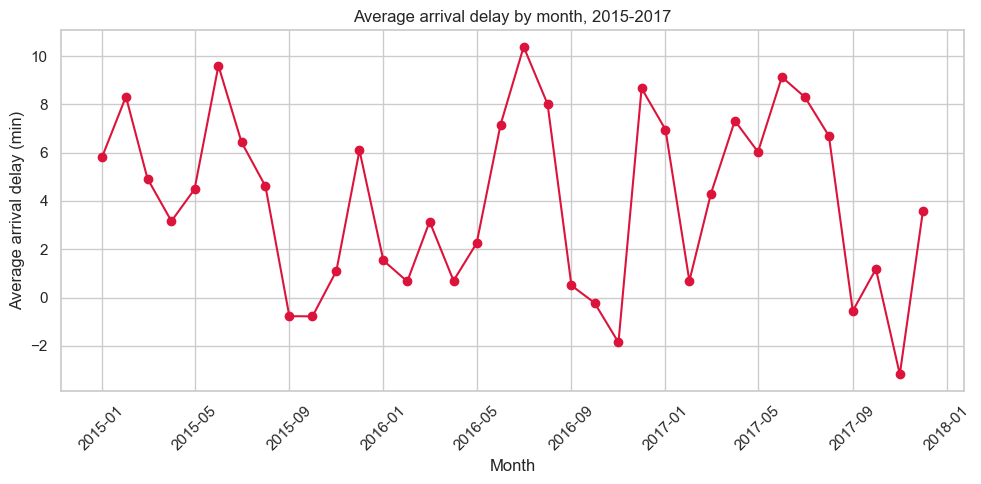

In [16]:
monthly = flights.groupby(['YEAR', 'MONTH'], observed=True).agg(
    avg_arr_delay=('ARR_DELAY', 'mean'),
    n_flights=('ARR_DELAY', 'size'),
    cancel_rate=('CANCELLED', 'mean'),
).reset_index()
monthly['YEAR_MONTH'] = pd.to_datetime(monthly['YEAR'].astype(str) + '-' + monthly['MONTH'].astype(str) + '-01')
monthly = monthly.sort_values('YEAR_MONTH')

fig, ax = plt.subplots()
ax.plot(monthly['YEAR_MONTH'], monthly['avg_arr_delay'], marker='o', color='crimson')
ax.set_title('Average arrival delay by month, 2015-2017')
ax.set_xlabel('Month')
ax.set_ylabel('Average arrival delay (min)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


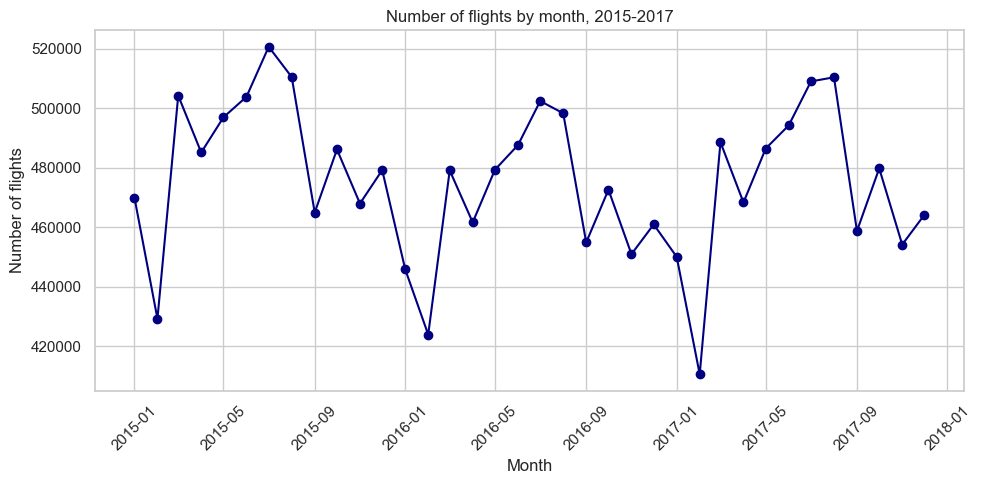

In [17]:
fig, ax = plt.subplots()
ax.plot(monthly['YEAR_MONTH'], monthly['n_flights'], marker='o', color='navy')
ax.set_title('Number of flights by month, 2015-2017')
ax.set_xlabel('Month')
ax.set_ylabel('Number of flights')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


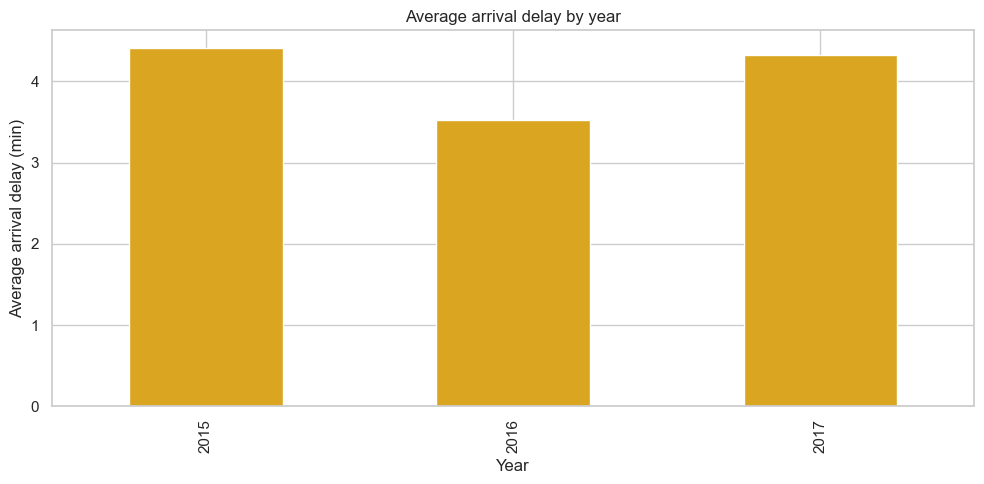

YEAR
2015    4.407057
2016    3.519290
2017    4.326357
Name: ARR_DELAY, dtype: float32

In [18]:
yearly_avg_delay = flights.groupby('YEAR', observed=True)['ARR_DELAY'].mean()

fig, ax = plt.subplots()
yearly_avg_delay.plot(kind='bar', ax=ax, color='goldenrod')
ax.set_title('Average arrival delay by year')
ax.set_xlabel('Year')
ax.set_ylabel('Average arrival delay (min)')
plt.tight_layout()
plt.show()

yearly_avg_delay


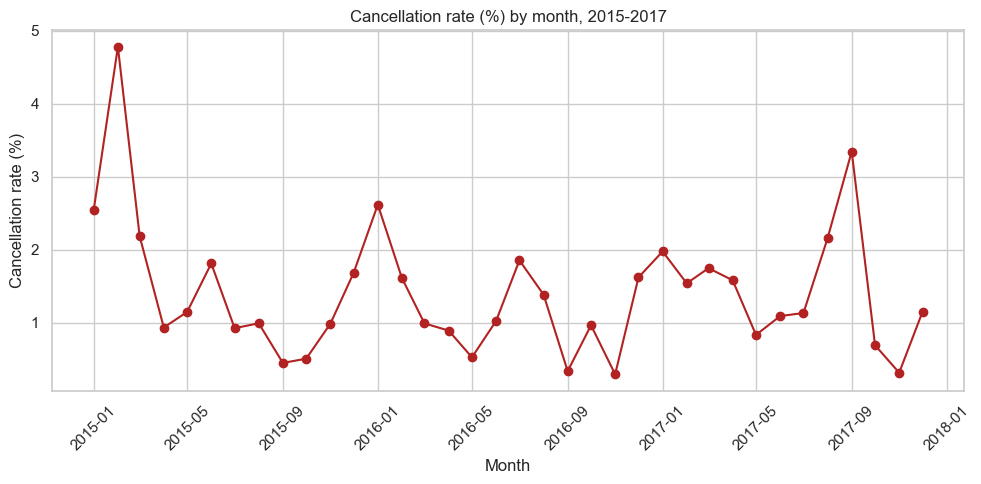

In [19]:
fig, ax = plt.subplots()
ax.plot(monthly['YEAR_MONTH'], monthly['cancel_rate'] * 100, marker='o', color='firebrick')
ax.set_title('Cancellation rate (%) by month, 2015-2017')
ax.set_xlabel('Month')
ax.set_ylabel('Cancellation rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


_Interpretation._ There is clear seasonality. Average arrival delay by month
peaks in the summer (Jun-Aug) and again around December/January, consistent with
higher traffic volume and convective-weather disruption in summer and winter
weather in midwinter. The cancellation rate shows an even sharper seasonal
pattern: the single worst month is **February 2015 at 4.78% cancelled** (the
well-documented severe winter of early 2015), while the best month is November
2016 at 0.29%. Year-over-year, the average arrival delay was 4.41 min (2015),
3.52 min (2016), and 4.33 min (2017) - 2016 was a noticeably better year than
2015 or 2017, but the levels are broadly similar across the three years.

### 3.2 Day of week and time of day

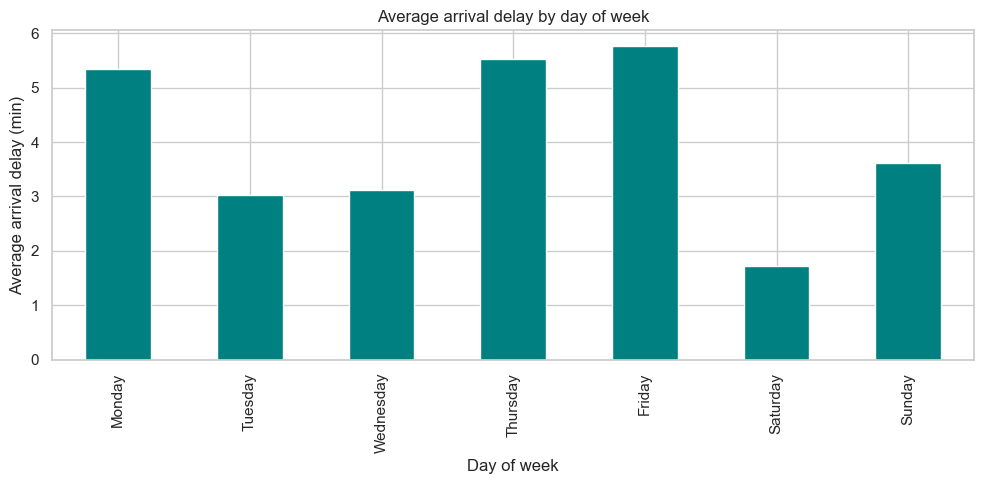

DAY_OF_WEEK
Monday       5.336877
Tuesday      3.025706
Wednesday    3.111962
Thursday     5.527442
Friday       5.764270
Saturday     1.730598
Sunday       3.620081
Name: ARR_DELAY, dtype: float32

In [20]:
dow_delay = flights.groupby('DAY_OF_WEEK', observed=True)['ARR_DELAY'].mean()

fig, ax = plt.subplots()
dow_delay.plot(kind='bar', ax=ax, color='teal')
ax.set_title('Average arrival delay by day of week')
ax.set_xlabel('Day of week')
ax.set_ylabel('Average arrival delay (min)')
plt.tight_layout()
plt.show()

dow_delay


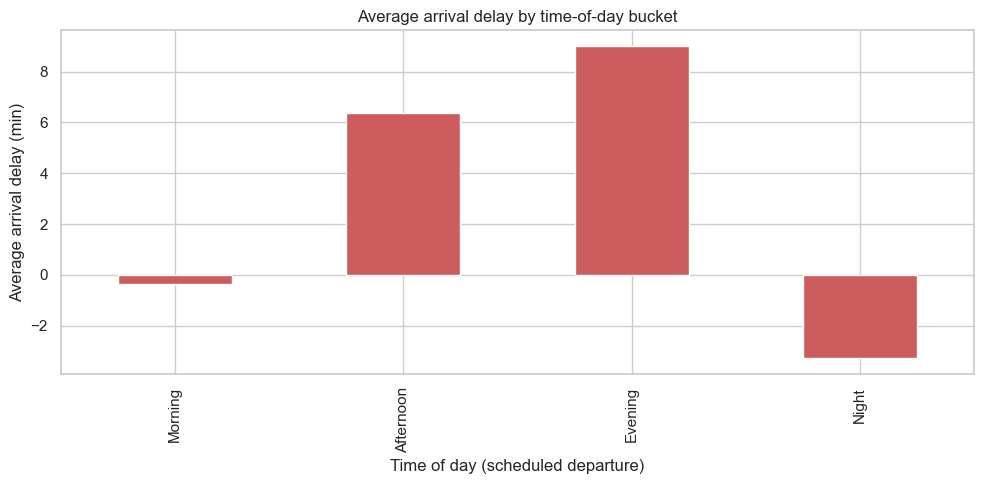

TIME_OF_DAY
Morning     -0.363968
Afternoon    6.389877
Evening      9.013238
Night       -3.297127
Name: ARR_DELAY, dtype: float32

In [21]:
tod_delay = flights.groupby('TIME_OF_DAY', observed=True)['ARR_DELAY'].mean()

fig, ax = plt.subplots()
tod_delay.plot(kind='bar', ax=ax, color='indianred')
ax.set_title('Average arrival delay by time-of-day bucket')
ax.set_xlabel('Time of day (scheduled departure)')
ax.set_ylabel('Average arrival delay (min)')
plt.tight_layout()
plt.show()

tod_delay


_Interpretation._ Delays build up over the course of the day, exactly as the
operational knock-on story predicts. Morning flights (06-11) average -0.36 min
arrival delay (essentially on time), Afternoon (12-17) averages +6.39 min,
Evening (18-23) averages +9.01 min, and Night (00-05) is back to -3.30 min.
By day of week, the weekend is the best: Saturday averages only +1.73 min and
Sunday +3.62 min. The worst weekdays are Friday (+5.76 min), Thursday (+5.53 min),
and Monday (+5.34 min), while Tuesday (+3.03 min) and Wednesday (+3.11 min) are
middling - consistent with business-travel peaks on Monday morning and Thursday/
Friday evening, and lighter schedules on Saturday. This is purely descriptive;
no causal mechanism is implied.

## 4. Carriers, airports, and routes

### 4.1 Carrier comparison

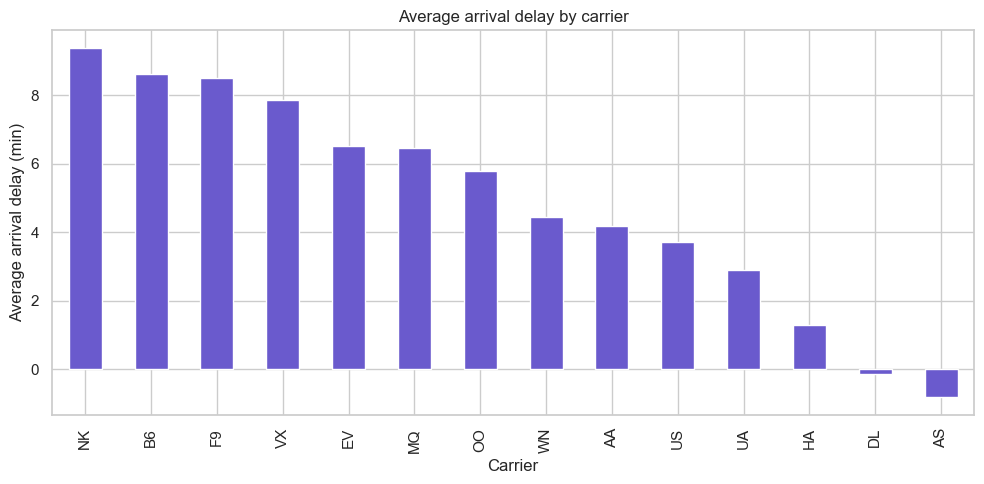

,avg_arr_delay,cancel_rate,n_flights
OP_CARRIER,,,
NK,9.390782,0.023701,412396
B6,8.639344,0.019290,848175
F9,8.522854,0.009457,288984
VX,7.877673,0.011069,202005
EV,6.531578,0.026443,1402508
MQ,6.457873,0.050996,294632
OO,5.798531,0.015185,1900813
WN,4.446432,0.012839,3890743
AA,4.182379,0.013373,2536827


In [22]:
carrier_stats = flights.groupby('OP_CARRIER', observed=True).agg(
    avg_arr_delay=('ARR_DELAY', 'mean'),
    cancel_rate=('CANCELLED', 'mean'),
    n_flights=('OP_CARRIER', 'size'),
).sort_values('avg_arr_delay', ascending=False)

fig, ax = plt.subplots()
carrier_stats['avg_arr_delay'].plot(kind='bar', ax=ax, color='slateblue')
ax.set_title('Average arrival delay by carrier')
ax.set_xlabel('Carrier')
ax.set_ylabel('Average arrival delay (min)')
plt.tight_layout()
plt.show()

carrier_stats


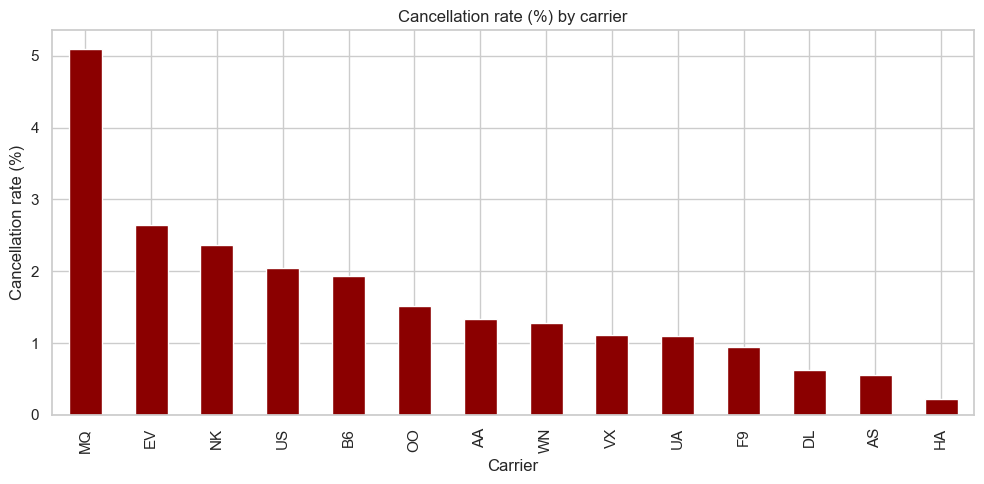

In [23]:
fig, ax = plt.subplots()
carrier_stats.sort_values('cancel_rate', ascending=False)['cancel_rate'].mul(100).plot(
    kind='bar', ax=ax, color='darkred'
)
ax.set_title('Cancellation rate (%) by carrier')
ax.set_xlabel('Carrier')
ax.set_ylabel('Cancellation rate (%)')
plt.tight_layout()
plt.show()


_Interpretation._ Carriers rank quite differently on delay vs cancellation.
By average arrival delay, the best performer is **Alaska (AS, -0.83 min)** followed
by Delta (DL, -0.15 min) and Hawaiian (HA, +1.29 min); the worst is **Spirit (NK,
+9.39 min)** followed by JetBlue (B6, +8.64 min) and Frontier (F9, +8.52 min). By
cancellation rate, the best is **Hawaiian (HA, 0.22%)** followed by Alaska (AS,
0.56%) and Delta (DL, 0.62%); the worst is **Envoy/Mesa (MQ, 5.10%)** followed by
ExpressJet/Atlantic Southeast (EV, 2.64%) and Spirit (NK, 2.37%). The carriers
that do well on delay also tend to do well on cancellation (AS, DL, HA at the top
of both), and the low-cost carriers NK/B6/F9 do poorly on delay. MQ and EV
(ExpressJet/Envoy) are regional carriers with disproportionately high cancellation
rates despite middling average delays - a different operational story.

### 4.2 Origin and destination patterns

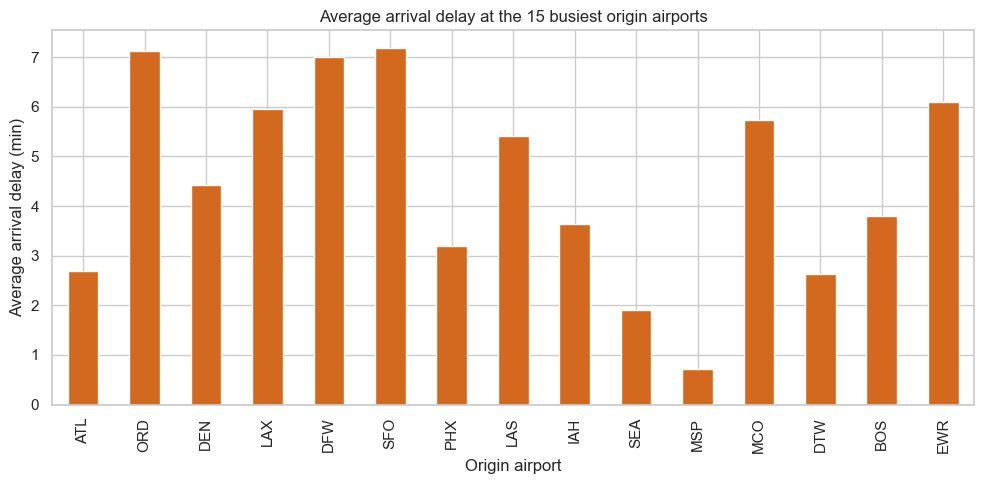

In [24]:
busiest_origins = flights['ORIGIN'].value_counts().head(15).index
origin_delay = (
    flights[flights['ORIGIN'].isin(busiest_origins)]
    .groupby('ORIGIN', observed=True)['ARR_DELAY']
    .mean()
    .reindex(busiest_origins)
)

fig, ax = plt.subplots()
origin_delay.plot(kind='bar', ax=ax, color='chocolate')
ax.set_title('Average arrival delay at the 15 busiest origin airports')
ax.set_xlabel('Origin airport')
ax.set_ylabel('Average arrival delay (min)')
plt.tight_layout()
plt.show()


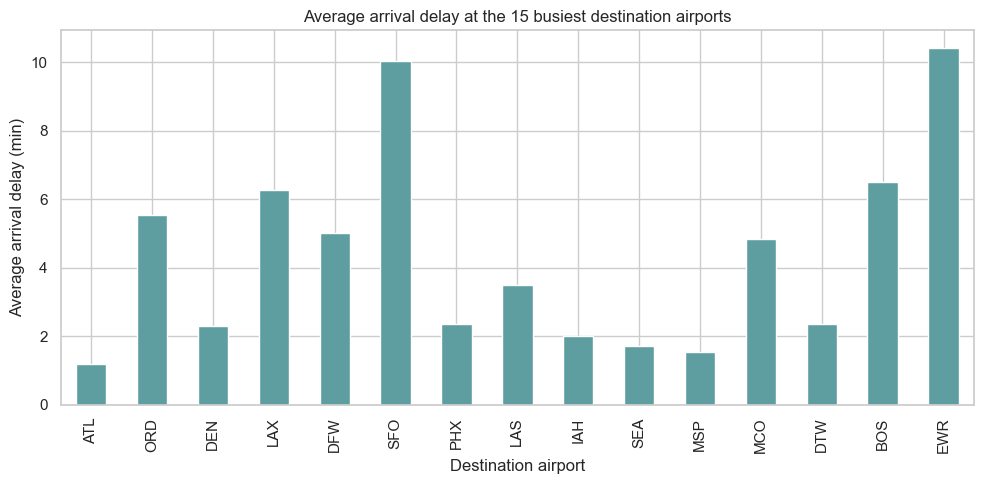

In [25]:
busiest_dests = flights['DEST'].value_counts().head(15).index
dest_delay = (
    flights[flights['DEST'].isin(busiest_dests)]
    .groupby('DEST', observed=True)['ARR_DELAY']
    .mean()
    .reindex(busiest_dests)
)

fig, ax = plt.subplots()
dest_delay.plot(kind='bar', ax=ax, color='cadetblue')
ax.set_title('Average arrival delay at the 15 busiest destination airports')
ax.set_xlabel('Destination airport')
ax.set_ylabel('Average arrival delay (min)')
plt.tight_layout()
plt.show()


In [26]:
# A few busy routes (origin-destination pairs), by flight count
flights['ROUTE'] = flights['ORIGIN'].astype(str) + '-' + flights['DEST'].astype(str)
top_routes = flights['ROUTE'].value_counts().head(10).index

route_stats = (
    flights[flights['ROUTE'].isin(top_routes)]
    .groupby('ROUTE', observed=True)
    .agg(avg_arr_delay=('ARR_DELAY', 'mean'), n_flights=('ROUTE', 'size'))
    .reindex(top_routes)
)
route_stats


,avg_arr_delay,n_flights
ROUTE,,
SFO-LAX,13.593961,48585
LAX-SFO,15.199353,47680
JFK-LAX,-0.135905,38434
LAX-JFK,3.651511,38424
LAS-LAX,11.954514,33166
LAX-LAS,9.136959,33068
LGA-ORD,2.185740,30898
ORD-LGA,9.667500,30586
SEA-LAX,5.007203,29024


## 5. Relationships between variables

### 5.1 Departure delay vs arrival delay

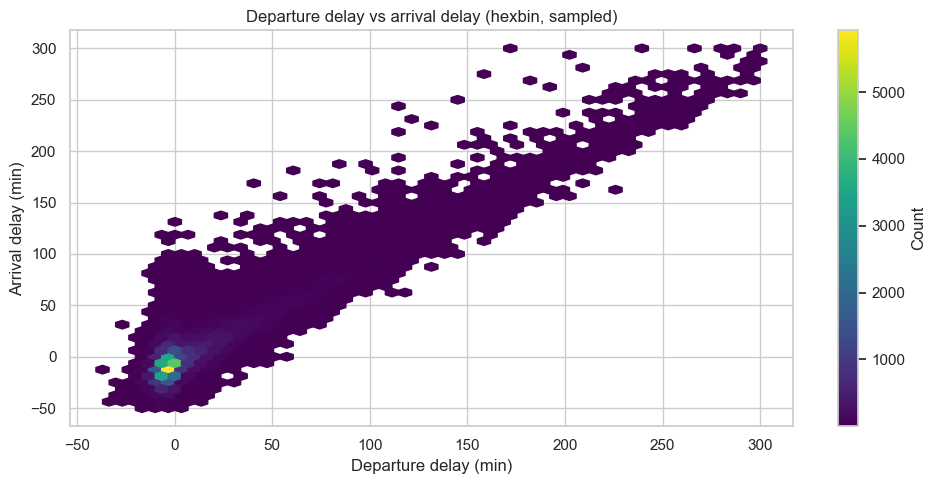

Correlation (Pearson): 0.954


In [27]:
sample = flights[['DEP_DELAY', 'ARR_DELAY']].dropna().sample(n=min(50000, flights['DEP_DELAY'].notna().sum()), random_state=RANDOM_SEED)

fig, ax = plt.subplots()
hb = ax.hexbin(sample['DEP_DELAY'].clip(-50, 300), sample['ARR_DELAY'].clip(-50, 300),
                gridsize=50, cmap='viridis', mincnt=1)
ax.set_title('Departure delay vs arrival delay (hexbin, sampled)')
ax.set_xlabel('Departure delay (min)')
ax.set_ylabel('Arrival delay (min)')
fig.colorbar(hb, ax=ax, label='Count')
plt.tight_layout()
plt.show()

print('Correlation (Pearson):', sample['DEP_DELAY'].corr(sample['ARR_DELAY']).round(3))


_Interpretation._ As expected, departure delay and arrival delay are very
strongly correlated: Pearson r = 0.954 on the 50,000-flight sample (and 0.952 on
the full dataset). A flight that leaves late almost always arrives late by a
similar margin. The hexbin plot shows a tight diagonal band with some spread
above the diagonal (flights that lose a little more time in the air) and below it
(flights that make up some of the departure delay en route).

### 5.2 Distance vs arrival delay

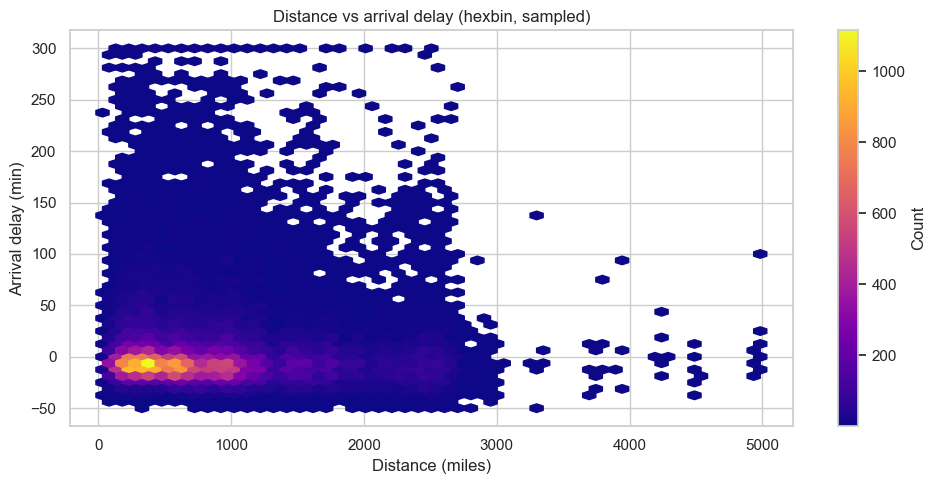

Correlation (Pearson): -0.011


In [28]:
dist_sample = flights[['DISTANCE', 'ARR_DELAY']].dropna().sample(
    n=min(50000, flights['DISTANCE'].notna().sum()), random_state=RANDOM_SEED
)

fig, ax = plt.subplots()
hb = ax.hexbin(dist_sample['DISTANCE'], dist_sample['ARR_DELAY'].clip(-50, 300),
                gridsize=50, cmap='plasma', mincnt=1)
ax.set_title('Distance vs arrival delay (hexbin, sampled)')
ax.set_xlabel('Distance (miles)')
ax.set_ylabel('Arrival delay (min)')
fig.colorbar(hb, ax=ax, label='Count')
plt.tight_layout()
plt.show()

print('Correlation (Pearson):', dist_sample['DISTANCE'].corr(dist_sample['ARR_DELAY']).round(3))


_Interpretation._ Distance and arrival delay are essentially uncorrelated
(r = -0.011 on the sample, -0.020 on the full dataset). Flight length alone is
not a meaningful driver of delay. The hexbin is dense near the bottom of the plot
across the whole distance range, with no clear trend - both short-haul and
long-haul flights show the same wide vertical spread in arrival delay, though
short-haul flights are more numerous and show slightly more variance at the
extreme tail, consistent with tighter turnaround schedules.

## 5.3 Correlation matrix and delay causes

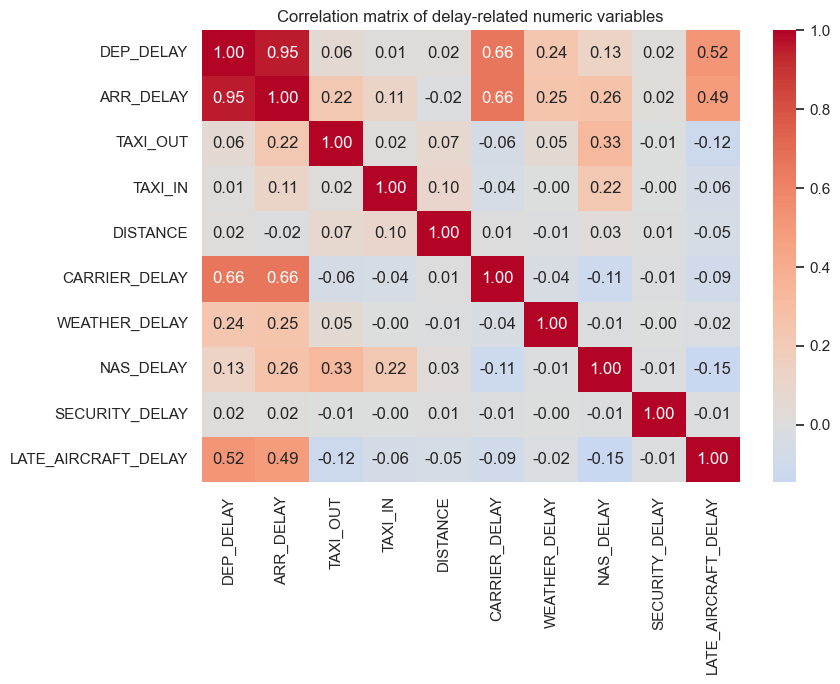

In [29]:
numeric_cols = ['DEP_DELAY', 'ARR_DELAY', 'TAXI_OUT', 'TAXI_IN', 'DISTANCE',
                 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']
corr = flights[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation matrix of delay-related numeric variables')
plt.tight_layout()
plt.show()


In [ ]:
# Delay causes: restrict to flights with ARR_DELAY >= 15, where cause columns are populated
delayed = flights[flights['ARR_DEL15'] == 1]
cause_totals = delayed[cause_cols].fillna(0).sum().sort_values(ascending=False)
cause_share = (cause_totals / cause_totals.sum() * 100).round(2)

cause_summary = pd.DataFrame({'total_minutes': cause_totals, 'share_pct': cause_share})
cause_summary


,total_minutes,share_pct
LATE_AIRCRAFT_DELAY,74325392.0,39.470001
CARRIER_DELAY,60222996.0,31.980000
NAS_DELAY,45007168.0,23.900000
WEATHER_DELAY,8506075.0,4.520000
SECURITY_DELAY,257080.0,0.140000


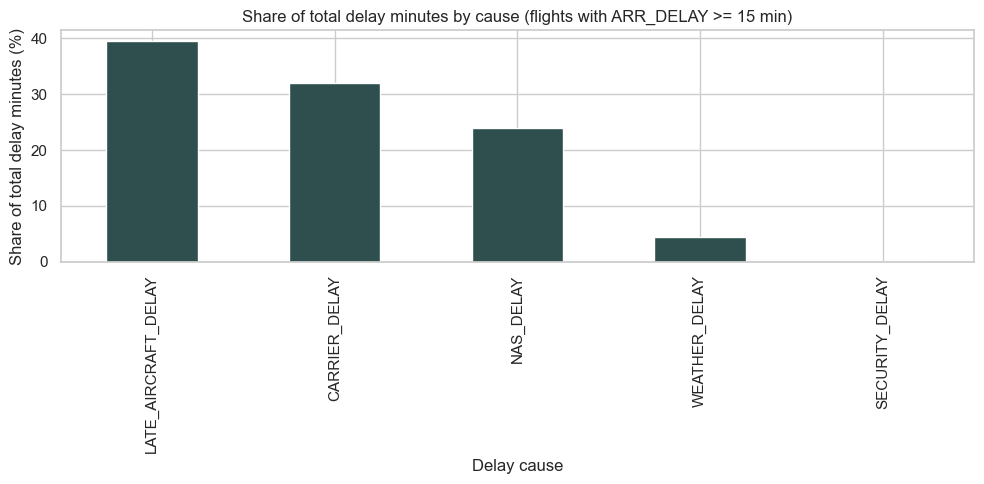

In [31]:
fig, ax = plt.subplots()
cause_share.plot(kind='bar', ax=ax, color='darkslategray')
ax.set_title('Share of total delay minutes by cause (flights with ARR_DELAY >= 15 min)')
ax.set_xlabel('Delay cause')
ax.set_ylabel('Share of total delay minutes (%)')
plt.tight_layout()
plt.show()


_Interpretation._ The correlation heatmap shows the expected structure:
`ARR_DELAY` is most strongly correlated with `DEP_DELAY` (r = 0.95) and then with
the operational cause columns `CARRIER_DELAY` (0.66) and `LATE_AIRCRAFT_DELAY`
(0.49). `DISTANCE` is essentially uncorrelated with delay (|r| <= 0.08 with every
other variable). The five delay-cause columns are roughly independent of one
another (|r| <= 0.15), which makes sense - they are defined as additive
components of a flight's total delay.

Among the 3,057,152 flights delayed by at least 15 minutes, the share of total
delay minutes by cause is: **Late aircraft 39.5%, Carrier 32.0%, NAS (national
airspace system) 23.9%, Weather 4.5%, Security 0.1%**. So delay in 2015-2017 is
dominated by airline operational factors and knock-on late-aircraft effects;
weather and security - despite disproportionate public attention - account for
under 5% of total delay minutes combined.

## 6. Summary of findings

- **Scale:** 17,111,358 domestic flights across 2015-2017, dominated by a handful
  of large carriers (WN, DL, AA, OO, UA) and major hubs (ATL, ORD, DEN, LAX, DFW).
- **Typical flight runs early:** median arrival delay is -6 min; the positive mean
  (4.1 min) is driven by a long right tail (max 2,189 min). Only 1.39% of flights
  were cancelled, 0.24% diverted.
- **Seasonality:** average delay and cancellation rate spike in midwinter
  (February 2015 was the worst month at 4.78% cancelled) and summer; 2016 was a
  better year than 2015 or 2017.
- **Within-week pattern:** delays accumulate through the day (Morning -0.4 min ->
  Evening +9.0 min) and are lowest on Saturday; Friday/Thursday/Monday are the
  worst weekdays.
- **Carriers diverge:** Alaska, Delta, and Hawaiian lead on both low delay and
  low cancellation; Spirit, JetBlue, and Frontier have the largest average
  delays; regional carriers MQ and EV have disproportionately high cancellation
  rates.
- **Delay causes:** among flights delayed >= 15 min, late-aircraft (39.5%) and
  carrier (32.0%) delay dominate; weather (4.5%) and security (0.1%) are minor.
- **Strongest relationship:** departure and arrival delay are near-perfectly
  correlated (r = 0.95). Distance is uncorrelated with delay (r ~ 0).